### Name :- Dev Sharma
### CU24250269
### BTech CSE 3rd Year SECTION - "B"
### Roll No. :- 17

###============================================================
### Experiment No. 1
### Experiment Name
### Real-World Data Collection, Cleaning and Preprocessing
### using Python
###============================================================

### Aim:
### To collect a real-world dataset from publicly available
### sources and perform data preprocessing by handling missing
### values, duplicate records, inconsistent formats, categorical
### variables, and outliers using Python.

##GITHUB LINK :-https://github.com/DevSharma1912/Mastery-in-Data-Analytics-and-Visualizations-and-Career-Advancement-Technical-/tree/main/Mastery%20in%20Data%20Analytics%20and%20Visualizations%20and%20Career%20Advancement%20(Technical)/Experiment1

Step 1: Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tkinter import Tk, filedialog
from sklearn.preprocessing import LabelEncoder, StandardScaler


Step 2: Upload / Select Dataset from Computer

In [ ]:
import io
from google.colab import files

print("Please select a CSV file to upload.")

uploaded = files.upload()

if not uploaded:
    print("No dataset selected.")
else:
    file_name = next(iter(uploaded)) # Get the name of the first uploaded file
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

    print("Dataset loaded successfully.")
    print("Selected Dataset:", file_name)

Please select a CSV file to upload.


Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv
Dataset loaded successfully.
Selected Dataset: WA_Fn-UseC_-HR-Employee-Attrition.csv


Step 3: Display First Five Records

In [ ]:
print("\n========== FIRST FIVE RECORDS ==========")

print(df.head())



========== FIRST FIVE RECORDS ==========
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction

Step 4: Display Dataset Information

In [ ]:
print("\n========== DATASET INFORMATION ==========")

print(df.info())


========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-

Step 5: Display Statistical Description

In [ ]:
print("\n========== STATISTICAL DESCRIPTION ==========")

print(df.describe(include="all"))


========== STATISTICAL DESCRIPTION ==========
                Age Attrition BusinessTravel    DailyRate  \
count   1470.000000      1470           1470  1470.000000   
unique          NaN         2              3          NaN   
top             NaN        No  Travel_Rarely          NaN   
freq            NaN      1233           1043          NaN   
mean      36.923810       NaN            NaN   802.485714   
std        9.135373       NaN            NaN   403.509100   
min       18.000000       NaN            NaN   102.000000   
25%       30.000000       NaN            NaN   465.000000   
50%       36.000000       NaN            NaN   802.000000   
75%       43.000000       NaN            NaN  1157.000000   
max       60.000000       NaN            NaN  1499.000000   

                    Department  DistanceFromHome    Education EducationField  \
count                     1470       1470.000000  1470.000000           1470   
unique                       3               NaN          Na

Step 6: Check Dataset Shape

In [ ]:
print("\n========== DATASET SHAPE ==========")

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])




========== DATASET SHAPE ==========
Number of Rows: 1470
Number of Columns: 35




Step 7: Identify Missing Values



In [ ]:
print("\n========== MISSING VALUES ==========")

missing_values = df.isnull().sum()

print(missing_values)



========== MISSING VALUES ==========
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
Ye

Step 8: Handle Missing Values

In [ ]:
# Numerical columns -> Median
numerical_columns = df.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(
            df[column].median()
        )

# Categorical columns -> Mode
categorical_columns = df.select_dtypes(
    exclude=np.number
).columns

for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        mode_value = df[column].mode()

        if len(mode_value) > 0:
            df[column] = df[column].fillna(
                mode_value[0]
            )

print("\n========== MISSING VALUE HANDLING ==========")

print("Numerical missing values filled using Median.")
print("Categorical missing values filled using Mode.")

print("\nRemaining Missing Values:")

print(df.isnull().sum().sum())




========== MISSING VALUE HANDLING ==========
Numerical missing values filled using Median.
Categorical missing values filled using Mode.

Remaining Missing Values:
0


Step 9: Detect Duplicate Records

In [ ]:
duplicate_count = df.duplicated().sum()

print("\n========== DUPLICATE RECORDS ==========")

print("Number of Duplicate Records:", duplicate_count)

# Remove duplicates
df = df.drop_duplicates()

print("Duplicate Records Removed Successfully.")
print("Remaining Rows:", len(df))



========== DUPLICATE RECORDS ==========
Number of Duplicate Records: 0
Duplicate Records Removed Successfully.
Remaining Rows: 1470


Step 10: Standardize Categorical Values

In [ ]:
print("\n========== CATEGORICAL DATA ==========")

categorical_columns = df.select_dtypes(
    exclude=np.number
).columns

for column in categorical_columns:

    # Remove unnecessary spaces
    df[column] = df[column].astype(str).str.strip()

    # Convert text values to consistent lowercase format
    df[column] = df[column].str.lower()

print("Categorical values standardized successfully.")


========== CATEGORICAL DATA ==========
Categorical values standardized successfully.


Step 11: Encode Categorical Variables

In [ ]:
encoded_df = df.copy()

categorical_columns = encoded_df.select_dtypes(
    exclude=np.number
).columns

label_encoder = LabelEncoder()

for column in categorical_columns:

    encoded_df[column] = label_encoder.fit_transform(
        encoded_df[column].astype(str)
    )

print("Categorical variables encoded successfully.")
print("Encoding Method: Label Encoding")

Categorical variables encoded successfully.
Encoding Method: Label Encoding


Step 12: Detect Outliers using IQR Method

In [ ]:
print("\n========== OUTLIER DETECTION ==========")

numeric_columns = encoded_df.select_dtypes(
    include=np.number
).columns

outlier_summary = {}

for column in numeric_columns:

    Q1 = encoded_df[column].quantile(0.25)
    Q3 = encoded_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = encoded_df[
        (encoded_df[column] < lower_bound) |
        (encoded_df[column] > upper_bound)
    ]

    outlier_summary[column] = len(outliers)

    print(
        column,
        "-> Outliers:",
        len(outliers)
    )




========== OUTLIER DETECTION ==========
Age -> Outliers: 0
Attrition -> Outliers: 237
BusinessTravel -> Outliers: 0
DailyRate -> Outliers: 0
Department -> Outliers: 0
DistanceFromHome -> Outliers: 0
Education -> Outliers: 0
EducationField -> Outliers: 0
EmployeeCount -> Outliers: 0
EmployeeNumber -> Outliers: 0
EnvironmentSatisfaction -> Outliers: 0
Gender -> Outliers: 0
HourlyRate -> Outliers: 0
JobInvolvement -> Outliers: 0
JobLevel -> Outliers: 0
JobRole -> Outliers: 0
JobSatisfaction -> Outliers: 0
MaritalStatus -> Outliers: 0
MonthlyIncome -> Outliers: 114
MonthlyRate -> Outliers: 0
NumCompaniesWorked -> Outliers: 52
Over18 -> Outliers: 0
OverTime -> Outliers: 0
PercentSalaryHike -> Outliers: 0
PerformanceRating -> Outliers: 226
RelationshipSatisfaction -> Outliers: 0
StandardHours -> Outliers: 0
StockOptionLevel -> Outliers: 85
TotalWorkingYears -> Outliers: 63
TrainingTimesLastYear -> Outliers: 238
WorkLifeBalance -> Outliers: 0
YearsAtCompany -> Outliers: 104
YearsInCurrentRol

Step 13: Visualize Outliers using Box Plots

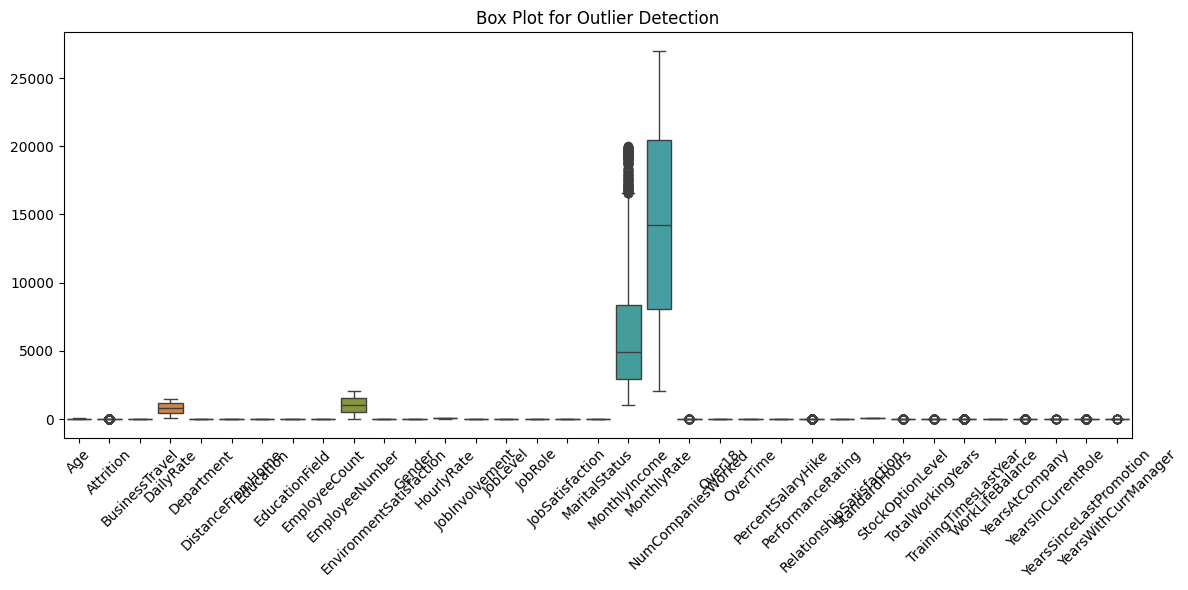

Box Plot generated successfully.


In [ ]:
boxplot_columns = encoded_df.select_dtypes(
    include=np.number
).columns

if len(boxplot_columns) > 0:

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=encoded_df[boxplot_columns]
    )

    plt.title("Box Plot for Outlier Detection")
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

print("Box Plot generated successfully.")

Step 14: Treat Outliers using IQR Capping

In [ ]:
for column in numeric_columns:

    Q1 = encoded_df[column].quantile(0.25)
    Q3 = encoded_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    encoded_df[column] = encoded_df[column].clip(
        lower_bound,
        upper_bound
    )

print("Outliers treated using IQR Capping.")

Outliers treated using IQR Capping.


Step 15: Normalize / Standardize Numerical Attributes

In [ ]:
numeric_columns = encoded_df.select_dtypes(
    include=np.number
).columns

scaler = StandardScaler()

if len(numeric_columns) > 0:

    encoded_df[numeric_columns] = scaler.fit_transform(
        encoded_df[numeric_columns]
    )

print("\n========== FEATURE SCALING ==========")

print("Numerical attributes standardized successfully.")
print("Scaling Method: Standardization")
print("Mean approximately equals 0.")
print("Standard deviation approximately equals 1.")




========== FEATURE SCALING ==========
Numerical attributes standardized successfully.
Scaling Method: Standardization
Mean approximately equals 0.
Standard deviation approximately equals 1.


Step 16: Feature Engineering

In [ ]:
if "sibsp" in encoded_df.columns and "parch" in encoded_df.columns:

    encoded_df["family_size"] = (
        encoded_df["sibsp"] +
        encoded_df["parch"] +
        1
    )

    print("\nFeature Created: family_size")


# If Age is available, create AgeGroup
if "age" in df.columns:

    age_values = df["age"]

    encoded_df["age_group"] = pd.cut(
        age_values,
        bins=[0, 12, 18, 35, 60, 100],
        labels=[
            "child",
            "teenager",
            "adult",
            "middle_aged",
            "senior"
        ]
    )

    # Encode Age Group
    encoded_df["age_group"] = LabelEncoder().fit_transform(
        encoded_df["age_group"].astype(str)
    )

    print("Feature Created: age_group")




Step 17: Display Preprocessed Dataset

In [ ]:
print("\n========== PREPROCESSED DATASET ==========")

print(encoded_df.head())



========== PREPROCESSED DATASET ==========
        Age  Attrition  BusinessTravel  DailyRate  Department  \
0  0.446350        0.0        0.590048   0.742527    1.401512   
1  1.322365        0.0       -0.913194  -1.297775   -0.493817   
2  0.008343        0.0        0.590048   1.414363   -0.493817   
3 -0.429664        0.0       -0.913194   1.461466   -0.493817   
4 -1.086676        0.0        0.590048  -0.524295   -0.493817   

   DistanceFromHome  Education  EducationField  EmployeeCount  EmployeeNumber  \
0         -1.010909  -0.891688       -0.937414            0.0       -1.701283   
1         -0.147150  -1.868426       -0.937414            0.0       -1.699621   
2         -0.887515  -0.891688        1.316673            0.0       -1.696298   
3         -0.764121   1.061787       -0.937414            0.0       -1.694636   
4         -0.887515  -1.868426        0.565311            0.0       -1.691313   

   ...  RelationshipSatisfaction  StandardHours  StockOptionLevel  \
0  ...   

Step 18: Display Final Dataset Information

In [ ]:
print("\n========== FINAL DATASET INFORMATION ==========")

print("Rows:", encoded_df.shape[0])
print("Columns:", encoded_df.shape[1])

print("\nMissing Values:")
print(encoded_df.isnull().sum().sum())

print("\nDuplicate Records:")
print(encoded_df.duplicated().sum())


========== FINAL DATASET INFORMATION ==========
Rows: 1470
Columns: 35

Missing Values:
0

Duplicate Records:
0


Step 19: Save Cleaned Dataset

In [ ]:

output_file = "cleaned_preprocessed_dataset.csv"

encoded_df.to_csv(
    output_file,
    index=False
)

print("\n========== DATASET STORAGE ==========")

print(
    "Cleaned Dataset Saved Successfully:",
    output_file
)




========== DATASET STORAGE ==========
Cleaned Dataset Saved Successfully: cleaned_preprocessed_dataset.csv


 Step 20: Final Output

In [ ]:
print("\n========== DATA PREPROCESSING ==========")

print("Dataset Collection: Completed")
print("Dataset Loading: Completed")
print("Data Inspection: Completed")
print("Missing Value Handling: Completed")
print("Duplicate Removal: Completed")
print("Categorical Standardization: Completed")
print("Categorical Encoding: Completed")
print("Outlier Detection: Completed")
print("Outlier Treatment: Completed")
print("Feature Standardization: Completed")
print("Feature Engineering: Completed")
print("Cleaned Dataset Export: Completed")

print("\nObservations:")

print("Missing numerical values were handled using the median.")
print("Missing categorical values were handled using the mode.")
print("Duplicate records were removed.")
print("Categorical values were standardized and encoded.")
print("Outliers were detected using the IQR method.")
print("Outliers were treated using IQR capping.")
print("Numerical features were standardized using StandardScaler.")
print("New features were created where applicable.")

print("\nExperiment Completed Successfully.")



========== DATA PREPROCESSING ==========
Dataset Collection: Completed
Dataset Loading: Completed
Data Inspection: Completed
Missing Value Handling: Completed
Duplicate Removal: Completed
Categorical Standardization: Completed
Categorical Encoding: Completed
Outlier Detection: Completed
Outlier Treatment: Completed
Feature Standardization: Completed
Feature Engineering: Completed
Cleaned Dataset Export: Completed

Observations:
Missing numerical values were handled using the median.
Missing categorical values were handled using the mode.
Duplicate records were removed.
Categorical values were standardized and encoded.
Outliers were detected using the IQR method.
Outliers were treated using IQR capping.
Numerical features were standardized using StandardScaler.
New features were created where applicable.

Experiment Completed Successfully.


EXPERIMENT 1 - ANSWERS TO QUESTIONS


QUESTION 1:
Why is data preprocessing considered one of the most important phases in data analytics?

Data preprocessing is important because real-world data is often incomplete, inconsistent, duplicated and noisy.

Before performing visualization, statistical analysis or machine learning, the data must be cleaned and prepared.

Data preprocessing helps to:

Handle missing values.
Remove duplicate records.
Correct inconsistent data.
Detect and treat outliers.
Convert categorical variables into numerical form.
Bring numerical features to a common scale.

Proper preprocessing improves the quality and reliability of analytical results.


QUESTION 2:
Explain different methods of handling missing values with suitable examples.

Missing values can be handled using several methods.

Mean:
Missing numerical values can be replaced by the mean of the available values.

Median:
Missing numerical values can be replaced by the median. Median is useful when the data contains outliers.

Mode:
Missing categorical values can be replaced by the most frequently occurring value.

Row Removal:
Rows containing missing values can be removed when the number of missing records is small.

Column Removal:
A column can be removed when a very large portion of its values is missing.

Example:

If the Age column contains missing values:

df["Age"] = df["Age"].fillna(df["Age"].median())

This replaces missing Age values with the median age.


QUESTION 3:
Differentiate between Label Encoding and One-Hot Encoding.

Label Encoding:

Label Encoding converts categories into numerical labels.

Example:

Male → 0
Female → 1

It is useful when categories have an inherent order or when a compact numerical representation is required.

One-Hot Encoding:

One-Hot Encoding creates separate binary columns for each category.

Example:

Gender

Male
Female

becomes:

Male Female
1 0
0 1

Main Difference:

Label Encoding → One numerical value per category.
One-Hot Encoding → Separate binary column for each category.


QUESTION 4:
What are outliers? How can they affect analytical results?

Outliers are observations that are significantly different from the majority of values in a dataset.

They can occur because of:

Measurement errors.
Data entry errors.
Unusual events.
Natural variation.

Outliers can affect:

Mean and standard deviation.
Statistical analysis.
Correlation.
Machine learning models.
Data visualization.

The IQR method can be used to identify outliers.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR


QUESTION 5:
Explain the difference between normalization and standardization.

Normalization:

Normalization generally scales values to a fixed range, commonly 0 to 1.

A common formula is:

X_normalized = (X - X_min) / (X_max - X_min)

Standardization:

Standardization transforms values so that the feature has approximately mean 0 and standard deviation 1.

Formula:

X_standardized = (X - Mean) / Standard Deviation

Main Difference:

Normalization → Fixed range, commonly 0 to 1.
Standardization → Mean approximately 0 and standard deviation approximately 1.


QUESTION 6:
Why should duplicate records be removed before analysis?

Duplicate records represent repeated observations of the same data.

If duplicates are not removed, they can:

Increase the apparent frequency of certain observations.
Produce biased statistical results.
Affect averages and distributions.
Affect machine learning model training.
Increase the apparent size of the dataset.

Removing duplicate records helps ensure that each observation is represented appropriately in the dataset.


QUESTION 7:
What is feature engineering? Give two practical examples.

Feature engineering is the process of creating new useful attributes from existing data.

It can help represent information in a form that is more useful for analysis or machine learning.

Example 1:

Family Size can be created from:

SibSp + Parch + 1

FamilySize = SibSp + Parch + 1

Example 2:

Age Group can be created from Age.

For example:

0-12 → Child
13-18 → Teenager
19-35 → Adult
36-60 → Middle Aged
60+ → Senior

Feature engineering can provide additional useful information without collecting new raw data.


QUESTION 8:
Which preprocessing techniques would you apply to the IBM HR Employee Attrition dataset and why?

For the IBM HR Employee Attrition dataset, the following preprocessing techniques can be applied:

Missing Value Handling:
Identify and appropriately handle missing values.

Duplicate Removal:
Remove duplicate employee records.

Categorical Encoding:
Convert categorical attributes such as department, job role and marital status into numerical form.

Outlier Detection:
Use box plots and the IQR method for numerical variables.

Feature Scaling:
Standardize numerical features such as age, income and years of experience where appropriate.

Feature Engineering:
Create useful attributes such as age groups or income categories.

These techniques improve data quality and prepare the employee dataset for statistical analysis and machine learning.


QUESTION 9:
How does poor-quality data affect machine learning model performance?

Poor-quality data can negatively affect machine learning models.

Problems such as:

Missing values.
Duplicate records.
Incorrect values.
Outliers.
Inconsistent categories.
Different numerical scales.

can cause models to learn incorrect or misleading patterns.

This may result in:

Lower prediction accuracy.
Poor generalization.
Biased predictions.
Unstable models.
Reduced reliability.

Therefore, high-quality preprocessing is important for building reliable machine learning models.


QUESTION 10:
Name any three Python libraries commonly used for data preprocessing.

Three commonly used Python libraries are:

Pandas:
Used for loading, cleaning, manipulating and analyzing structured datasets.

NumPy:
Used for numerical operations and array processing.

Scikit-learn:
Provides preprocessing tools such as LabelEncoder, StandardScaler and other machine learning utilities.

Other useful libraries include Matplotlib and Seaborn for visualization and exploratory data analysis.